In [ ]:
# ======================================================
# Cell 1: Install Dependencies
# ======================================================
import subprocess, sys

for _pkg in ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "openpyxl"]:
    subprocess.check_call([sys.executable, "-m", "pip", "install", _pkg, "-q"])

print("All dependencies installed.")

In [ ]:
# ======================================================
# Cell 2: Platform Detection & Path Configuration
# ======================================================
import os, sys

IS_COLAB = "google.colab" in sys.modules

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    ROOT_DIR = "/content/drive/MyDrive"
    print("Running on Google Colab - Google Drive mounted.")
else:
    ROOT_DIR = os.path.dirname(os.getcwd())
    print(f"Running locally - root: {ROOT_DIR}")

RESULTS_DIR = os.path.join(ROOT_DIR, "RESULTS")
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Results folder: {RESULTS_DIR}")

def pick_file(title="Select a file", filetypes=(("Excel files", "*.xlsx"),)):
    """Returns a file path - uses Colab uploader online, prompts for path offline."""
    if IS_COLAB:
        from google.colab import files as _colab_files
        uploaded = _colab_files.upload()
        if not uploaded:
            raise RuntimeError("No file uploaded.")
        fname = next(iter(uploaded))
        path = f"/tmp/{fname}"
        with open(path, "wb") as fh:
            fh.write(uploaded[fname])
        return path
    else:
        print(f"\n{title}")
        print("   Paste the full path to your file and press Enter.")
        print("   Example: /Users/you/project/Datasets/mapped-dataset-36-20.xlsx")
        path = input("   Path: ").strip().strip('"').strip("'")
        if not path:
            raise RuntimeError("No path entered.")
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"File not found at:\n  {path}\nCheck the path and re-run this cell."
            )
        return path

print("Platform setup complete.")

Please upload your file (CSV or Excel).
Required columns: tc_id, us_id, tc_executiontime, us_businessvalue


Saving D1.xlsx to D1.xlsx
Successfully loaded 'D1.xlsx'


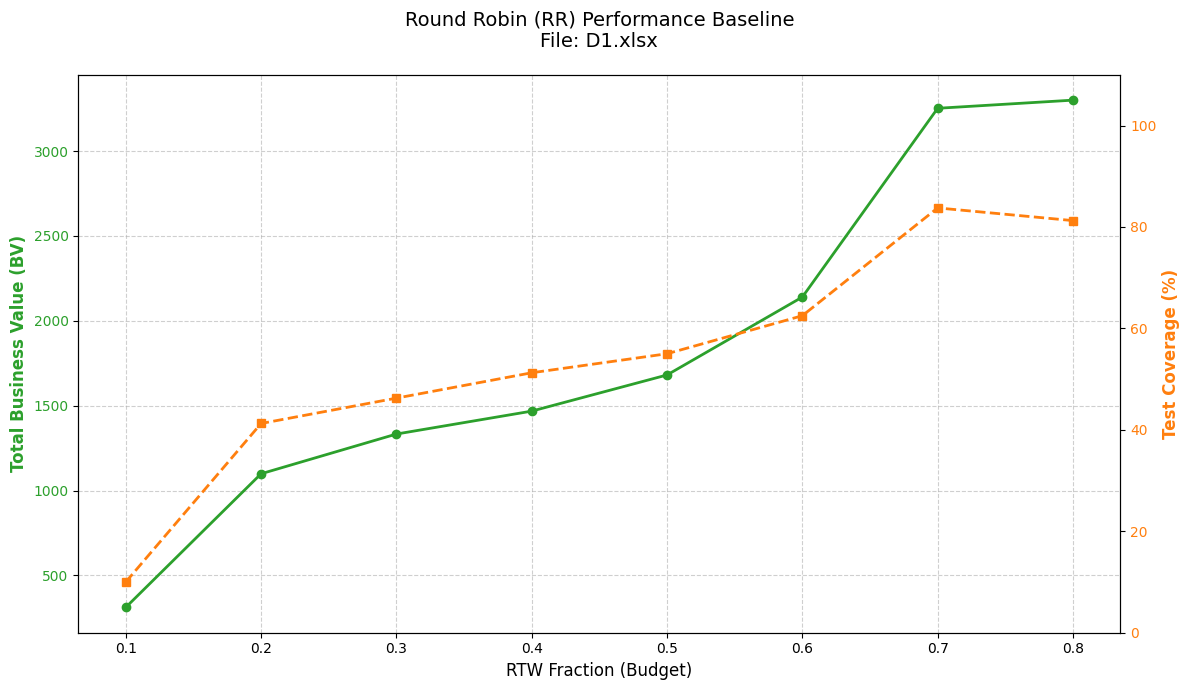

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, Any, Sequence
import os

# --------------------------------------------------------------------
# 1. FILE LOADING
# --------------------------------------------------------------------
filename = pick_file("Select your dataset file (CSV or Excel)")
print(f"Loading: {filename}")
if filename.lower().endswith(('.xlsx', '.xls')):
    df_input = pd.read_excel(filename)
else:
    df_input = pd.read_csv(filename, encoding='utf-8', errors='replace')
print(f"Successfully loaded '{os.path.basename(filename)}'")


# CONFIG: RTW_FRACTIONS
RTW_FRACTIONS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

# --------------------------------------------------------------------
# 2. ROUND ROBIN MODEL BUILDING & ALGORITHM FUNCTIONS
# --------------------------------------------------------------------
def build_model_rr(df: pd.DataFrame) -> Dict[str, Any]:
    """Build model for RR-based SUKP selection."""
    test_ids = np.sort(df["tc_id"].unique())
    req_ids  = np.sort(df["us_id"].unique())
    n_tests, n_reqs = len(test_ids), len(req_ids)

    test_index = {tc_id: i for i, tc_id in enumerate(test_ids)}
    req_index  = {us_id: i for i, us_id in enumerate(req_ids)}

    test_et = np.zeros(n_tests, dtype=float)
    for tc in test_ids:
        test_et[test_index[tc]] = float(df.loc[df["tc_id"] == tc, "tc_executiontime"].iloc[0])

    req_bv = np.zeros(n_reqs, dtype=float)
    for us in req_ids:
        req_bv[req_index[us]] = float(df.loc[df["us_id"] == us, "us_businessvalue"].iloc[0])

    # many–many mapping: Requirement -> Tests
    req_to_tests_idx = [[] for _ in range(n_reqs)]
    for _, row in df.iterrows():
        ti, rj = test_index[row["tc_id"]], req_index[row["us_id"]]
        req_to_tests_idx[rj].append(ti)

    return {
        "test_ids": test_ids, "req_ids": req_ids, "test_et": test_et, "req_bv": req_bv,
        "req_to_tests_idx": [np.array(tidx, dtype=int) for tidx in req_to_tests_idx],
        "n_tests": n_tests, "n_reqs": n_reqs
    }

def rr_sukp_single_rtw(model: Dict[str, Any], budget: float, start_req_index: int) -> Dict[str, Any]:
    """Single RTW selection using pure Round Robin over requirements."""
    n_tests, n_reqs = model["n_tests"], model["n_reqs"]
    test_et, req_bv = model["test_et"], model["req_bv"]
    req_to_tests_idx = model["req_to_tests_idx"]

    selected_tests = np.zeros(n_tests, dtype=bool)
    used_et = 0.0
    req_satisfied_rtw = np.zeros(n_reqs, dtype=bool)

    added_in_last_pass = True
    rr_head = start_req_index % n_reqs

    while added_in_last_pass:
        added_in_last_pass = False
        # One full cyclic pass starting from rr_head
        for offset in range(n_reqs):
            rj = (rr_head + offset) % n_reqs
            if req_satisfied_rtw[rj]: continue

            tests_idx = req_to_tests_idx[rj]
            if tests_idx.size == 0: continue

            # Compute extra ET needed for this requirement's tests
            extra_needed = 0.0
            to_add = []
            for ti in tests_idx:
                if not selected_tests[ti]:
                    extra_needed += test_et[ti]
                    to_add.append(ti)

            if extra_needed == 0.0:
                req_satisfied_rtw[rj] = True
                added_in_last_pass = True
                continue

            if used_et + extra_needed <= budget:
                for ti in to_add:
                    selected_tests[ti] = True
                used_et += extra_needed
                req_satisfied_rtw[rj] = True
                added_in_last_pass = True

        rr_head = (rr_head + 1) % n_reqs

    return {
        "total_bv": float(req_bv[req_satisfied_rtw].sum()),
        "test_coverage": 100.0 * float(selected_tests.sum()) / n_tests,
        "last_rr_index": rr_head
    }

def rr_sukp_over_rtws(df: pd.DataFrame, rtw_fractions: Sequence[float]) -> Dict[float, Dict[str, Any]]:
    """Run Round Robin across multiple budget steps, maintaining head state."""
    model = build_model_rr(df)
    total_et = model["test_et"].sum()
    results = {}
    rr_head = 0  # Persistence across RTWs

    for frac in rtw_fractions:
        rtw_result = rr_sukp_single_rtw(model, float(frac) * total_et, rr_head)
        rr_head = rtw_result["last_rr_index"]
        results[float(frac)] = rtw_result
    return results

# --------------------------------------------------------------------
# 3. EXECUTION & PLOTTING
# --------------------------------------------------------------------
results = rr_sukp_over_rtws(df_input, RTW_FRACTIONS)

fractions = sorted(results.keys())
bv_values = [results[f]['total_bv'] for f in fractions]
cvg_values = [results[f]['test_coverage'] for f in fractions]

fig, ax1 = plt.subplots(figsize=(12, 7))

# Plot BV (Primary Axis)
color_bv = 'tab:green'
ax1.set_xlabel('RTW Fraction (Budget)', fontsize=12)
ax1.set_ylabel('Total Business Value (BV)', color=color_bv, fontweight='bold', fontsize=12)
ax1.plot(fractions, bv_values, color=color_bv, marker='o', linewidth=2, label='BV')
ax1.tick_params(axis='y', labelcolor=color_bv)
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot Test Coverage (Secondary Axis)
ax2 = ax1.twinx()
color_cvg = 'tab:orange'
ax2.set_ylabel('Test Coverage (%)', color=color_cvg, fontweight='bold', fontsize=12)
ax2.plot(fractions, cvg_values, color=color_cvg, marker='s', linestyle='--', linewidth=2, label='Test Coverage')
ax2.tick_params(axis='y', labelcolor=color_cvg)
ax2.set_ylim(0, 110)

plt.title(f'Round Robin (RR) Performance Baseline\nFile: {filename}', fontsize=14, pad=20)
fig.tight_layout()
plt.show()